In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

print(os.getcwd())

C:\Users\ASUS\Product-Review-Intelligence\notebooks


In [4]:
print(os.listdir())

['.ipynb_checkpoints', 'sentiment_analysis.ipynb']


In [5]:
df = pd.read_csv("../data/Dataset-SA.csv")

df.head()

,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [6]:
print("Dataset shape:", df.shape)


Dataset shape: (205052, 6)


In [7]:
print(df.columns.tolist())

['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205052 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   product_name   205052 non-null  str  
 1   product_price  205052 non-null  str  
 2   Rate           205052 non-null  str  
 3   Review         180388 non-null  str  
 4   Summary        205041 non-null  str  
 5   Sentiment      205052 non-null  str  
dtypes: str(6)
memory usage: 39.7 MB


In [9]:
print(df["Sentiment"].value_counts())

Sentiment
positive    166581
negative     28232
neutral      10239
Name: count, dtype: int64


In [10]:
# Check missing values
df.isnull().sum()

product_name         0
product_price        0
Rate                 0
Review           24664
Summary             11
Sentiment            0
dtype: int64

In [11]:
# Calculate missing value percentage
(df.isnull().sum() / len(df)) * 100

product_name      0.000000
product_price     0.000000
Rate              0.000000
Review           12.028168
Summary           0.005364
Sentiment         0.000000
dtype: float64

In [12]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 34375


In [13]:
# Check unique sentiment labels
print(df["Sentiment"].unique())

<ArrowStringArray>
['positive', 'negative', 'neutral']
Length: 3, dtype: str


In [14]:
# Remove rows where Review is missing
df = df.dropna(subset=["Review"])

# Check remaining missing values
print(df.isnull().sum())

# Check the new dataset size
print("Dataset shape:", df.shape)

product_name     0
product_price    0
Rate             0
Review           0
Summary          9
Sentiment        0
dtype: int64
Dataset shape: (180388, 6)


In [15]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check remaining duplicates
print("Remaining duplicates:", df.duplicated().sum())

# Check updated dataset size
print("Dataset shape:", df.shape)

Remaining duplicates: 0
Dataset shape: (154475, 6)


In [16]:
# Remove leading and trailing spaces
df["Review"] = df["Review"].str.strip()

# Remove empty reviews
df = df[df["Review"] != ""]

# Check dataset shape
print("Dataset shape:", df.shape)

Dataset shape: (154475, 6)


In [17]:
# Convert sentiment labels to lowercase
df["Sentiment"] = df["Sentiment"].str.lower().str.strip()

# Check sentiment labels
print(df["Sentiment"].value_counts())

Sentiment
positive    122813
negative     23353
neutral       8309
Name: count, dtype: int64


In [18]:
# Save cleaned dataset
df.to_csv("../data/cleaned_reviews.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [19]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/cleaned_reviews.csv")

print("Dataset shape:", df.shape)

Dataset shape: (154475, 6)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_5852\3252918180.py:4: DtypeWarning: Columns (0: product_price, 1: Rate) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/cleaned_reviews.csv")


In [20]:
# Count each sentiment
sentiment_counts = df["Sentiment"].value_counts()

print(sentiment_counts)

Sentiment
positive    122813
negative     23353
neutral       8309
Name: count, dtype: int64


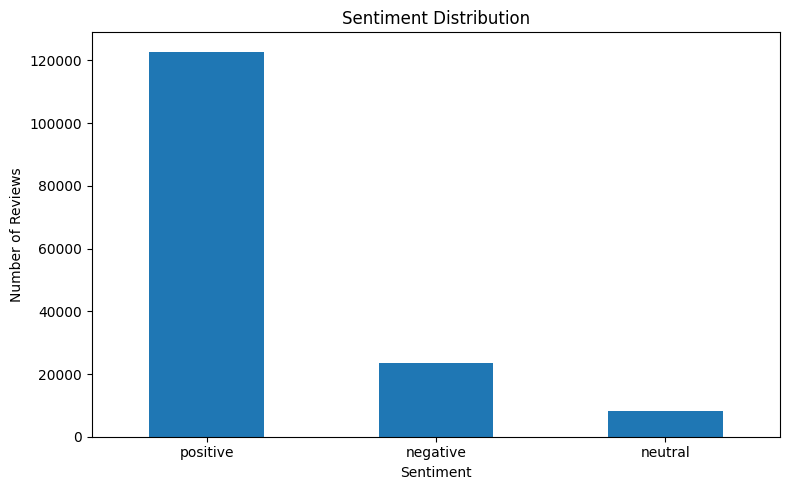

In [21]:
# Plot sentiment distribution
sentiment_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

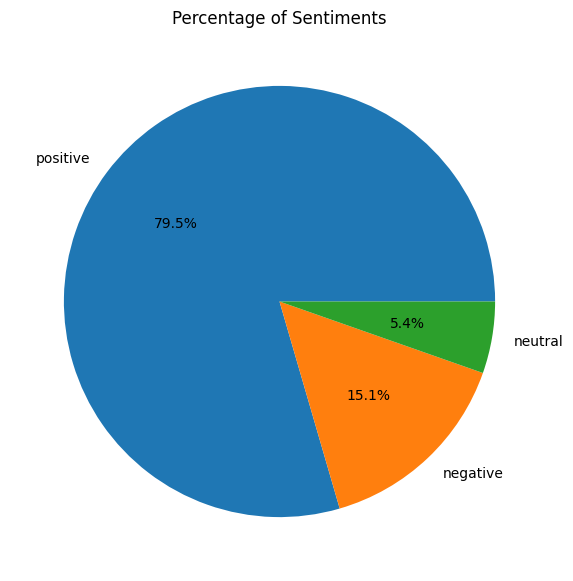

In [22]:
# Plot sentiment distribution as a pie chart
sentiment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Percentage of Sentiments")
plt.ylabel("")
plt.show()

In [23]:
# Calculate review length
df["Review_Length"] = df["Review"].astype(str).str.len()

# Display statistics
print(df["Review_Length"].describe())

count    154475.000000
mean         12.659835
std           5.091583
min           2.000000
25%           9.000000
50%          12.000000
75%          16.000000
max         140.000000
Name: Review_Length, dtype: float64


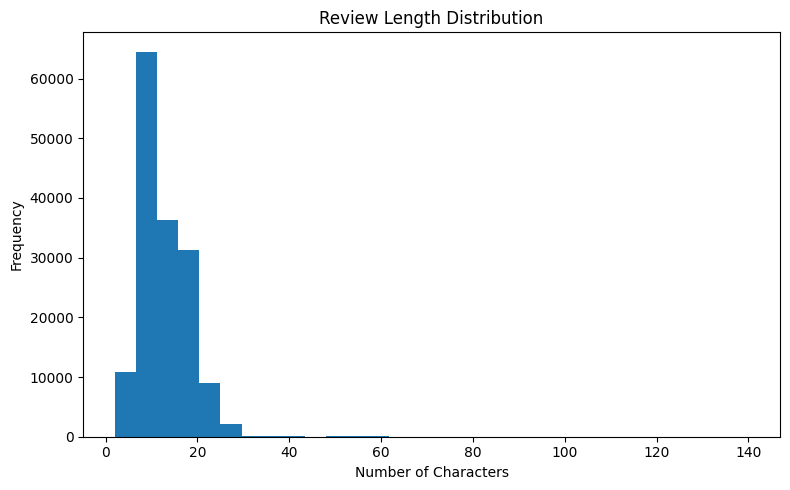

In [24]:
# Plot review length distribution
plt.figure(figsize=(8, 5))

plt.hist(df["Review_Length"], bins=30)

plt.title("Review Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [25]:
from collections import Counter
import re

# Combine all reviews
text = " ".join(df["Review"].dropna().astype(str))

# Extract words
words = re.findall(r"\b[a-zA-Z]+\b", text.lower())

# Find 20 most common words
common_words = Counter(words).most_common(20)

print(common_words)

[('product', 25790), ('good', 14847), ('the', 9591), ('awesome', 9561), ('purchase', 9310), ('terrific', 9260), ('not', 8869), ('money', 8163), ('nice', 7915), ('worth', 7653), ('wonderful', 7639), ('just', 6602), ('recommended', 5776), ('specified', 5714), ('great', 4899), ('brilliant', 4812), ('buy', 4803), ('perfect', 4801), ('every', 4772), ('best', 4772)]


In [26]:
import pandas as pd
import re
from sklearn.feature_extraction.text import TfidfVectorizer

In [27]:
df = pd.read_csv("../data/cleaned_reviews.csv")

print(df.shape)
df.head()

(154475, 6)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_5852\1198363689.py:1: DtypeWarning: Columns (0: product_price, 1: Rate) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/cleaned_reviews.csv")


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [28]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["Cleaned_Review"] = df["Review"].apply(clean_text)

df[["Review", "Cleaned_Review"]].head()

,Review,Cleaned_Review
0,super!,super
1,awesome,awesome
2,fair,fair
3,useless product,useless product
4,fair,fair


In [29]:
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["Cleaned_Review"])

print("TF-IDF shape:", X.shape)

TF-IDF shape: (154475, 1268)


In [30]:
y = df["Sentiment"]

print(y.value_counts())

Sentiment
positive    122813
negative     23353
neutral       8309
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (123580, 1268)
Testing data: (30895, 1268)


In [32]:
from sklearn.linear_model import LogisticRegression

# Create the model
model_lr = LogisticRegression(max_iter=1000)

# Train the model
model_lr.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [33]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict sentiment
y_pred_lr = model_lr.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred_lr)
print("Accuracy:", accuracy)

# Classification report
print(classification_report(y_test, y_pred_lr))

# Confusion matrix
print(confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.9026703350056643


C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              precision    recall  f1-score   support

    negative       0.84      0.78      0.81      4670
     neutral       0.00      0.00      0.00      1662
    positive       0.91      0.99      0.95     24563

    accuracy                           0.90     30895
   macro avg       0.58      0.59      0.59     30895
weighted avg       0.85      0.90      0.88     30895

[[ 3652     0  1018]
 [  363     0  1299]
 [  327     0 24236]]


C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [34]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
model_nb = MultinomialNB()

# Train the model
model_nb.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [35]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict sentiment
y_pred_nb = model_nb.predict(X_test)

# Calculate accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)
print("Naive Bayes Accuracy:", accuracy_nb)

# Classification report
print(classification_report(y_test, y_pred_nb))

# Confusion matrix
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.8978475481469493
              precision    recall  f1-score   support

    negative       0.84      0.76      0.80      4670
     neutral       0.06      0.00      0.01      1662
    positive       0.91      0.98      0.95     24563

    accuracy                           0.90     30895
   macro avg       0.61      0.58      0.58     30895
weighted avg       0.85      0.90      0.87     30895

[[ 3540    16  1114]
 [  339     5  1318]
 [  313    56 24194]]


In [36]:
print("Logistic Regression Accuracy:", accuracy)
print("Naive Bayes Accuracy:", accuracy_nb)

Logistic Regression Accuracy: 0.9026703350056643
Naive Bayes Accuracy: 0.8978475481469493


In [37]:
import pickle

# Select the model
best_model = model_lr

# Save the model
with open("../models/sentiment_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Best model saved successfully!")

Best model saved successfully!


In [38]:
!pip install streamlit


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
import pickle

with open("../models/tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(tfidf, file)

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!
